# GPU Architecture
:label:`ch_gpu_arch`


High-end GPUs often provide a significantly better performance over high-end CPUs. Although the terminologies and programming paradigms are different between GPUs and CPUs, their architectures are similar to each other, with GPU having a wider SIMD width and more cores. In this section, we will brief review the GPU architecture in comparison to the CPU architecture presented in :numref:`ch_cpu_arch`.

(FIXME, changed from V100 to T4 in CI..., also changed cpu...)

The system we are using has a [Tesla T4](https://www.nvidia.com/content/dam/en-zz/Solutions/design-visualization/technologies/turing-architecture/NVIDIA-Turing-Architecture-Whitepaper.pdf) GPU, which is based on Turing architecture. Tesla T4 is a GPU card based on the Turing architecture and targeted at deep learning model inference acceleration.


In [15]:
import os, time, math, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

os.makedirs("figures", exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# Chosen parameters per Nov 9 clarification
HIDDEN_SIZE = 64
SEEDS = [42, 123, 999]
RESULTS_PATH = "../results.csv"

CSV_COLS = [
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats", "bits_per_char", "notes"
]

def log_result(row_dict):
    df_new = pd.DataFrame([{c: row_dict.get(c, "") for c in CSV_COLS}])
    if os.path.exists(RESULTS_PATH):
        df_old = pd.read_csv(RESULTS_PATH)
        df = pd.concat([df_old, df_new], ignore_index=True)
    else:
        df = df_new
    df.to_csv(RESULTS_PATH, index=False)

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

Using device: cuda
Using device: cuda


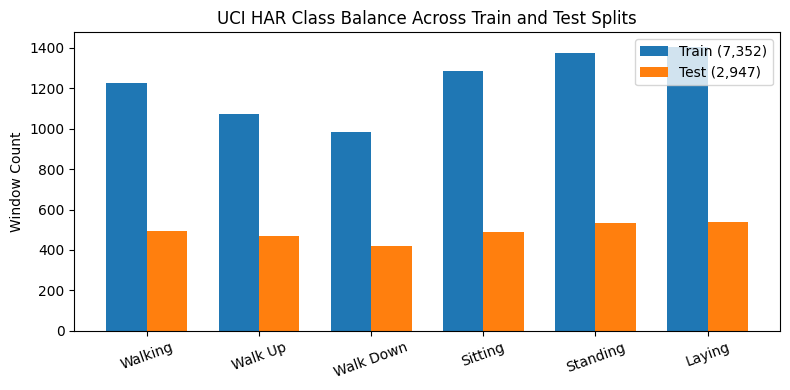

Adding problem unit tests passed!


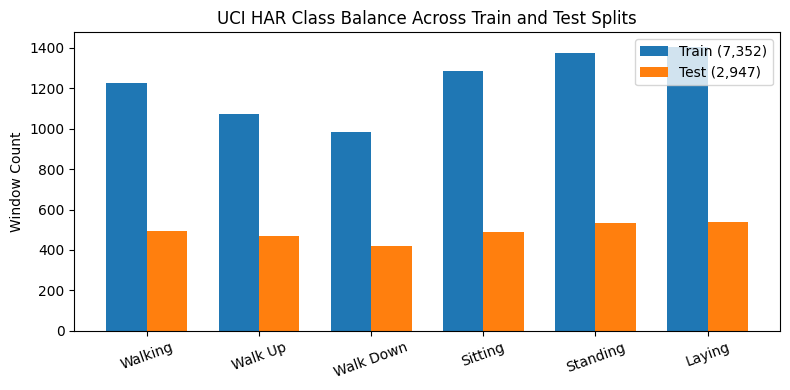

Adding problem unit tests passed!


In [16]:
def download_and_load_har():
    if not os.path.exists("UCI HAR Dataset"):
        url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
        urllib.request.urlretrieve(url, "har.zip")
        with zipfile.ZipFile("har.zip", "r") as zf:
            zf.extractall("har_temp")
        inner_zip = os.path.join("har_temp", "UCI HAR Dataset.zip")
        if os.path.exists(inner_zip):
            with zipfile.ZipFile(inner_zip, "r") as zf:
                zf.extractall(".")
        else:
            os.rename(os.path.join("har_temp", "UCI HAR Dataset"), "UCI HAR Dataset")

    signals = [
        "body_acc_x", "body_acc_y", "body_acc_z",
        "body_gyro_x", "body_gyro_y", "body_gyro_z",
        "total_acc_x", "total_acc_y", "total_acc_z"
    ]

    def load_split(split):
        data = []
        for sig in signals:
            path = f"UCI HAR Dataset/{split}/Inertial Signals/{sig}_{split}.txt"
            data.append(np.loadtxt(path, dtype=np.float32))
        X = np.stack(data, axis=-1)  # (N, 128, 9)
        y = np.loadtxt(f"UCI HAR Dataset/{split}/y_{split}.txt", dtype=np.int64) - 1
        subj = np.loadtxt(f"UCI HAR Dataset/{split}/subject_{split}.txt", dtype=np.int64)
        return X, y, subj

    return load_split("train"), load_split("test")

(X_train_raw, y_train_raw, subj_train), (X_test_raw, y_test_raw, subj_test) = download_and_load_har()
assert X_train_raw.shape == (7352, 128, 9) and X_test_raw.shape == (2947, 128, 9)

def get_har_split(seed):
    train_subjects = np.unique(subj_train)
    val_subjs = np.random.default_rng(seed).choice(train_subjects, 4, replace=False)
    val_mask = np.isin(subj_train, val_subjs)
    tr_mask = ~val_mask

    X_tr, y_tr = X_train_raw[tr_mask], y_train_raw[tr_mask]
    X_va, y_va = X_train_raw[val_mask], y_train_raw[val_mask]

    # Per-channel mean and std from training split only
    mean = X_tr.mean(axis=(0, 1), keepdims=True)
    std = X_tr.std(axis=(0, 1), keepdims=True) + 1e-8
    return (X_tr - mean) / std, y_tr, (X_va - mean) / std, y_va, (X_test_raw - mean) / std, y_test_raw

# Plot class balance
class_names = ["Walking", "Walk Up", "Walk Down", "Sitting", "Standing", "Laying"]
counts_tr = np.bincount(y_train_raw, minlength=6)
counts_te = np.bincount(y_test_raw, minlength=6)
x_idx = np.arange(6)
plt.figure(figsize=(8, 4))
plt.bar(x_idx - 0.18, counts_tr, width=0.36, label="Train (7,352)")
plt.bar(x_idx + 0.18, counts_te, width=0.36, label="Test (2,947)")
plt.xticks(x_idx, class_names, rotation=20)
plt.ylabel("Window Count")
plt.title("UCI HAR Class Balance Across Train and Test Splits")
plt.legend()
plt.tight_layout()
plt.savefig("figures/har_class_balance.png", dpi=200)
plt.show()

# Adding Problem Generator + Unit Test
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

# Unit test for make_adding
x_chk, y_chk = make_adding(500, 100, seed=0)
markers = x_chk[:, :, 1]
assert np.all(markers.sum(axis=1) == 2), "Each sequence must have exactly 2 markers"
assert np.all(markers[:, :50].sum(axis=1) == 1), "First half must have 1 marker"
assert np.all(markers[:, 50:].sum(axis=1) == 1), "Second half must have 1 marker"
expected_y = (x_chk[:, :, 0] * markers).sum(axis=1)
assert np.allclose(y_chk, expected_y, atol=1e-6), "Target must equal sum of marked values"
print("Adding problem unit tests passed!")

In [17]:
class MyRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.W_ih = nn.Parameter(torch.empty(hidden_size, input_size))
        self.W_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b = nn.Parameter(torch.zeros(hidden_size))

    def forward(self, x_t, h_prev):
        # x_t: (B, D), h_prev: (B, H)
        return torch.tanh(x_t @ self.W_ih.t() + h_prev @ self.W_hh.t() + self.b)

class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.H = hidden_size
        self.W_ih = nn.Parameter(torch.empty(4 * hidden_size, input_size))
        self.W_hh = nn.Parameter(torch.empty(4 * hidden_size, hidden_size))
        self.b = nn.Parameter(torch.zeros(4 * hidden_size))

    def forward(self, x_t, state):
        # x_t: (B, D), state: tuple of (h_prev, c_prev) each (B, H)
        h_prev, c_prev = state
        gates = x_t @ self.W_ih.t() + h_prev @ self.W_hh.t() + self.b  # (B, 4H)
        i, f, g, o = gates.chunk(4, dim=-1)  # PyTorch gate order: i, f, g, o
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)
        c_next = f * c_prev + i * g
        h_next = o * torch.tanh(c_next)
        return h_next, c_next

class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.H = hidden_size
        self.W_ih = nn.Parameter(torch.empty(3 * hidden_size, input_size))
        self.W_hh = nn.Parameter(torch.empty(3 * hidden_size, hidden_size))
        self.b_ih = nn.Parameter(torch.zeros(3 * hidden_size))
        self.b_hh = nn.Parameter(torch.zeros(3 * hidden_size))

    def forward(self, x_t, h_prev):
        # x_t: (B, D), h_prev: (B, H)
        gi = x_t @ self.W_ih.t() + self.b_ih  # (B, 3H)
        gh = h_prev @ self.W_hh.t() + self.b_hh  # (B, 3H)
        i_r, i_z, i_n = gi.chunk(3, dim=-1)
        h_r, h_z, h_n = gh.chunk(3, dim=-1)
        r = torch.sigmoid(i_r + h_r)
        z = torch.sigmoid(i_z + h_z)
        n = torch.tanh(i_n + r * h_n)
        h_next = (1 - z) * n + z * h_prev
        return h_next

# Unit test comparing against nn.RNN, nn.LSTM, nn.GRU within 1e-5
torch.manual_seed(0)
B, T, D, H = 8, 15, 9, 64
x_seq = torch.randn(B, T, D)

# 1. Verify RNN
ref_rnn = nn.RNN(D, H, batch_first=True)
my_rnn = MyRNNCell(D, H)
with torch.no_grad():
    my_rnn.W_ih.copy_(ref_rnn.weight_ih_l0)
    my_rnn.W_hh.copy_(ref_rnn.weight_hh_l0)
    my_rnn.b.copy_(ref_rnn.bias_ih_l0 + ref_rnn.bias_hh_l0)
h = torch.zeros(B, H)
outs = []
for t in range(T):
    h = my_rnn(x_seq[:, t, :], h)
    outs.append(h)
my_rnn_out = torch.stack(outs, dim=1)
ref_rnn_out, _ = ref_rnn(x_seq)
assert torch.allclose(my_rnn_out, ref_rnn_out, atol=1e-5), "MyRNNCell mismatch!"

# 2. Verify LSTM
ref_lstm = nn.LSTM(D, H, batch_first=True)
my_lstm = MyLSTMCell(D, H)
with torch.no_grad():
    my_lstm.W_ih.copy_(ref_lstm.weight_ih_l0)
    my_lstm.W_hh.copy_(ref_lstm.weight_hh_l0)
    my_lstm.b.copy_(ref_lstm.bias_ih_l0 + ref_lstm.bias_hh_l0)
h, c = torch.zeros(B, H), torch.zeros(B, H)
outs = []
for t in range(T):
    h, c = my_lstm(x_seq[:, t, :], (h, c))
    outs.append(h)
my_lstm_out = torch.stack(outs, dim=1)
ref_lstm_out, _ = ref_lstm(x_seq)
assert torch.allclose(my_lstm_out, ref_lstm_out, atol=1e-5), "MyLSTMCell mismatch!"

# 3. Verify GRU
ref_gru = nn.GRU(D, H, batch_first=True)
my_gru = MyGRUCell(D, H)
with torch.no_grad():
    my_gru.W_ih.copy_(ref_gru.weight_ih_l0)
    my_gru.W_hh.copy_(ref_gru.weight_hh_l0)
    my_gru.b_ih.copy_(ref_gru.bias_ih_l0)
    my_gru.b_hh.copy_(ref_gru.bias_hh_l0)
h = torch.zeros(B, H)
outs = []
for t in range(T):
    h = my_gru(x_seq[:, t, :], h)
    outs.append(h)
my_gru_out = torch.stack(outs, dim=1)
ref_gru_out, _ = ref_gru(x_seq)
assert torch.allclose(my_gru_out, ref_gru_out, atol=1e-5), "MyGRUCell mismatch!"

print("All from-scratch cells match PyTorch library implementations within 1e-5!")
print(f"Single-bias params (D=9, H=64): RNN={sum(p.numel() for p in my_rnn.parameters())}, "
      f"LSTM={sum(p.numel() for p in my_lstm.parameters())}, GRU={sum(p.numel() for p in my_gru.parameters()) - 3*H}")
print(f"PyTorch dual-bias params: RNN={sum(p.numel() for p in ref_rnn.parameters())}, "
      f"LSTM={sum(p.numel() for p in ref_lstm.parameters())}, GRU={sum(p.numel() for p in ref_gru.parameters())}")

All from-scratch cells match PyTorch library implementations within 1e-5!
Single-bias params (D=9, H=64): RNN=4736, LSTM=18944, GRU=14208
PyTorch dual-bias params: RNN=4800, LSTM=19200, GRU=14400
All from-scratch cells match PyTorch library implementations within 1e-5!
Single-bias params (D=9, H=64): RNN=4736, LSTM=18944, GRU=14208
PyTorch dual-bias params: RNN=4800, LSTM=19200, GRU=14400


            acc                  f1             params         sec_ep  \
           mean       std      mean       std     mean  std      mean   
model                                                                   
GRU    0.897636  0.012027  0.898109  0.012881  14790.0  0.0  0.170230   
LSTM   0.889831  0.002208  0.890513  0.002483  19590.0  0.0  0.178706   
RNN    0.713155  0.020811  0.702124  0.017639   5190.0  0.0  0.285783   

                 
            std  
model            
GRU    0.013825  
LSTM   0.019639  
RNN    0.111867  


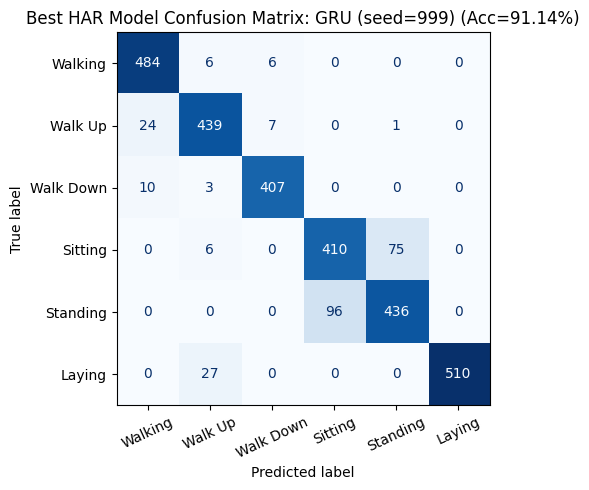

In [11]:
class SequenceClassifier(nn.Module):
    def __init__(self, cell_type, input_size=9, hidden_size=64, num_classes=6):
        super().__init__()
        if cell_type == "RNN":
            self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        elif cell_type == "LSTM":
            self.rnn = nn.LSTM(input_size, hidden_size, batch_first=True)
        elif cell_type == "GRU":
            self.rnn = nn.GRU(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])  # Classify from last hidden state

def train_har_model(cell_type, seed, hidden_size=64, epochs=25, batch_size=128):
    set_seed(seed)
    X_tr, y_tr, X_va, y_va, X_te, y_te = get_har_split(seed)
    tr_loader = DataLoader(TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr)), batch_size=batch_size, shuffle=True)
    va_loader = DataLoader(TensorDataset(torch.tensor(X_va), torch.tensor(y_va)), batch_size=batch_size)
    te_loader = DataLoader(TensorDataset(torch.tensor(X_te), torch.tensor(y_te)), batch_size=batch_size)

    model = SequenceClassifier(cell_type, 9, hidden_size, 6).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    best_val_acc, best_state = -1.0, None
    epoch_times = []

    for ep in range(epochs):
        t0 = time.time()
        model.train()
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
        epoch_times.append(time.time() - t0)

        model.eval()
        preds, targets = [], []
        with torch.no_grad():
            for xb, yb in va_loader:
                preds.append(model(xb.to(DEVICE)).argmax(dim=-1).cpu())
                targets.append(yb)
        val_acc = accuracy_score(torch.cat(targets), torch.cat(preds))
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for xb, yb in te_loader:
            preds.append(model(xb.to(DEVICE)).argmax(dim=-1).cpu())
            targets.append(yb)
    y_true, y_pred = torch.cat(targets).numpy(), torch.cat(preds).numpy()
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    params = sum(p.numel() for p in model.parameters())
    sec_ep = float(np.mean(epoch_times))
    return acc, f1, params, sec_ep, y_true, y_pred

har_records = []
best_overall = (-1.0, None, None, None)

for m_type in ["RNN", "LSTM", "GRU"]:
    for s in SEEDS:
        acc, f1, params, sec_ep, y_true, y_pred = train_har_model(m_type, s, hidden_size=HIDDEN_SIZE)
        har_records.append({"model": m_type, "seed": s, "acc": acc, "f1": f1, "params": params, "sec_ep": sec_ep})
        log_result({
            "problem": "P1_HAR", "model": m_type, "seed": s, "seq_len": 128,
            "test_acc": round(acc, 4), "macro_f1": round(f1, 4),
            "params": params, "sec_per_epoch": round(sec_ep, 4), "notes": f"h={HIDDEN_SIZE}"
        })
        if acc > best_overall[0]:
            best_overall = (acc, f"{m_type} (seed={s})", y_true, y_pred)

df_har = pd.DataFrame(har_records)
print(df_har.groupby("model")[["acc", "f1", "params", "sec_ep"]].agg(["mean", "std"]))

# Plot confusion matrix of best model
cm = confusion_matrix(best_overall[2], best_overall[3])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=25, colorbar=False)
plt.title(f"Best HAR Model Confusion Matrix: {best_overall[1]} (Acc={best_overall[0]:.2%})")
plt.tight_layout()
plt.savefig("figures/har_confusion_matrix.png", dpi=200)
plt.show()

                mse           solved
               mean       std    sum
T   model                           
50  GRU    0.002250  0.000747      3
    LSTM   0.018537  0.007747      3
    RNN    0.162537  0.022923      0
100 GRU    0.002580  0.000752      3
    LSTM   0.123622  0.079761      1
    RNN    0.169984  0.000373      0
200 GRU    0.003327  0.001735      3
    LSTM   0.169032  0.000776      0
    RNN    0.171430  0.003876      0
400 GRU    0.047735  0.048265      2
    LSTM   0.152826  0.000056      0
    RNN    0.153797  0.000700      0


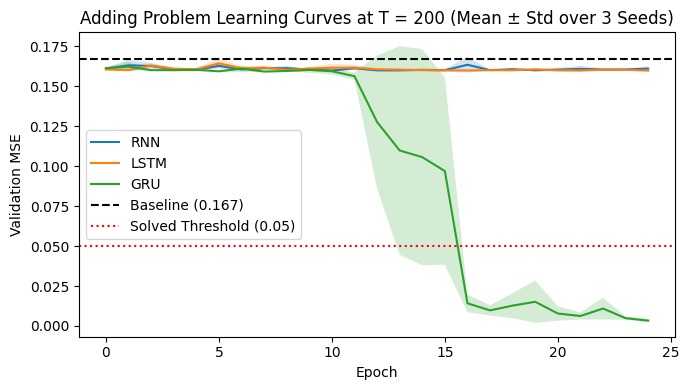

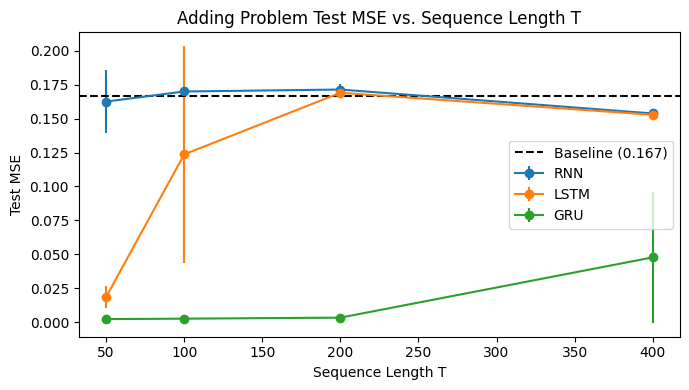

In [12]:
class SequenceRegressor(nn.Module):
    def __init__(self, cell_type, input_size=2, hidden_size=64, forget_bias=None):
        super().__init__()
        if cell_type == "RNN":
            self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        elif cell_type == "LSTM":
            self.rnn = nn.LSTM(input_size, hidden_size, batch_first=True)
            if forget_bias is not None:
                with torch.no_grad():
                    self.rnn.bias_ih_l0[hidden_size:2*hidden_size].fill_(forget_bias)
                    self.rnn.bias_hh_l0[hidden_size:2*hidden_size].fill_(0.0)
        elif cell_type == "GRU":
            self.rnn = nn.GRU(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :]).squeeze(-1)

def train_adding_model(cell_type, T, seed, hidden_size=64, epochs=25, batch_size=128, clip_norm=1.0, forget_bias=None):
    set_seed(seed)
    X_tr, y_tr = make_adding(10000, T, seed=0)
    X_va, y_va = make_adding(1000, T, seed=1)
    X_te, y_te = make_adding(1000, T, seed=2)

    tr_loader = DataLoader(TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr)), batch_size=batch_size, shuffle=True)
    model = SequenceRegressor(cell_type, 2, hidden_size, forget_bias=forget_bias).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    val_curve = []
    epoch_times = []
    for ep in range(epochs):
        t0 = time.time()
        model.train()
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = F.mse_loss(model(xb), yb)
            loss.backward()
            if clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_norm)
            opt.step()
        epoch_times.append(time.time() - t0)

        model.eval()
        with torch.no_grad():
            va_pred = model(torch.tensor(X_va, device=DEVICE))
            val_mse = F.mse_loss(va_pred, torch.tensor(y_va, device=DEVICE)).item()
            val_curve.append(val_mse)

    model.eval()
    with torch.no_grad():
        te_pred = model(torch.tensor(X_te, device=DEVICE))
        test_mse = F.mse_loss(te_pred, torch.tensor(y_te, device=DEVICE)).item()
    return test_mse, val_curve, sum(p.numel() for p in model.parameters()), float(np.mean(epoch_times)), model

adding_records = []
curves_T200 = {m: [] for m in ["RNN", "LSTM", "GRU"]}

for T in [50, 100, 200, 400]:
    for m_type in ["RNN", "LSTM", "GRU"]:
        for s in SEEDS:
            mse, curve, params, sec_ep, _ = train_adding_model(m_type, T, s, hidden_size=HIDDEN_SIZE, epochs=25)
            adding_records.append({"T": T, "model": m_type, "seed": s, "mse": mse, "solved": int(mse < 0.05)})
            if T == 200:
                curves_T200[m_type].append(curve)
            log_result({
                "problem": "P1_Adding", "model": m_type, "seed": s, "seq_len": T,
                "test_mse": round(mse, 5), "params": params, "sec_per_epoch": round(sec_ep, 4),
                "notes": f"h={HIDDEN_SIZE}, solved={mse < 0.05}"
            })

df_add = pd.DataFrame(adding_records)
print(df_add.groupby(["T", "model"])[["mse", "solved"]].agg({"mse": ["mean", "std"], "solved": "sum"}))

# Plot 1: Learning curves at T = 200
plt.figure(figsize=(7, 4))
for m_type in ["RNN", "LSTM", "GRU"]:
    arr = np.array(curves_T200[m_type])
    plt.plot(arr.mean(axis=0), label=m_type)
    plt.fill_between(range(arr.shape[1]), arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), alpha=0.2)
plt.axhline(0.167, color="k", linestyle="--", label="Baseline (0.167)")
plt.axhline(0.05, color="r", linestyle=":", label="Solved Threshold (0.05)")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Adding Problem Learning Curves at T = 200 (Mean ± Std over 3 Seeds)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/adding_curves_T200.png", dpi=200)
plt.show()

# Plot 2: Test MSE against T
plt.figure(figsize=(7, 4))
for m_type in ["RNN", "LSTM", "GRU"]:
    sub = df_add[df_add["model"] == m_type].groupby("T")["mse"].agg(["mean", "std"])
    plt.errorbar(sub.index, sub["mean"], yerr=sub["std"], marker="o", label=m_type)
plt.axhline(0.167, color="k", linestyle="--", label="Baseline (0.167)")
plt.xlabel("Sequence Length T")
plt.ylabel("Test MSE")
plt.title("Adding Problem Test MSE vs. Sequence Length T")
plt.legend()
plt.tight_layout()
plt.savefig("figures/adding_mse_vs_T.png", dpi=200)
plt.show()

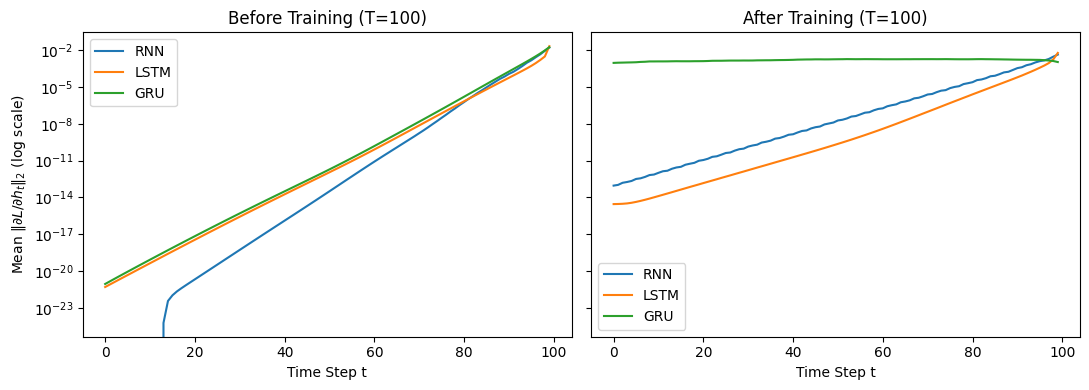

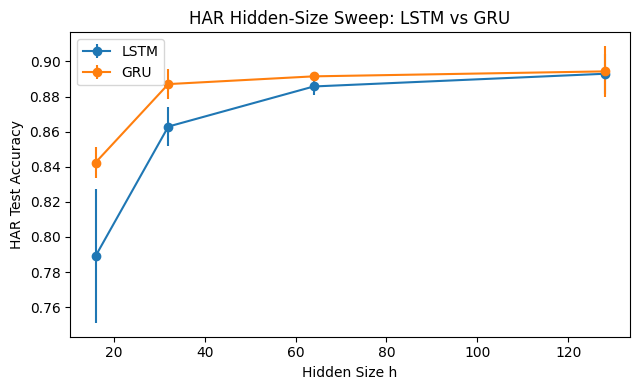

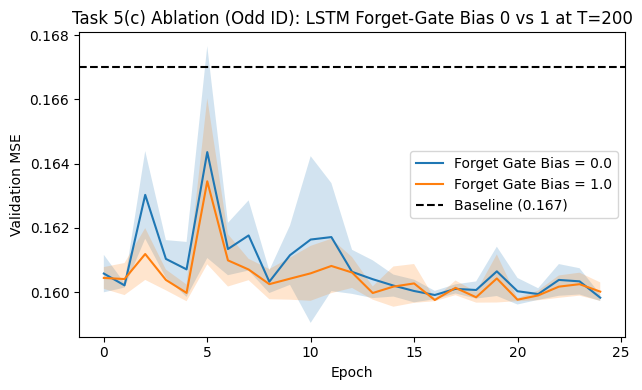

In [13]:
# 5(a) Gradient norm ||dL/dh_t|| at T = 100 before and after training
def compute_grad_norms(cell_type, trained_model=None):
    set_seed(42)
    X_sample, y_sample = make_adding(64, 100, seed=2)
    xb = torch.tensor(X_sample, device=DEVICE)
    yb = torch.tensor(y_sample, device=DEVICE)

    # Extract weights into our explicit step-by-step loop to retain intermediate h_t grads
    if trained_model is None:
        trained_model = SequenceRegressor(cell_type, 2, HIDDEN_SIZE).to(DEVICE)
    ref = trained_model.rnn
    fc = trained_model.fc

    if cell_type == "RNN":
        cell = MyRNNCell(2, HIDDEN_SIZE).to(DEVICE)
        with torch.no_grad():
            cell.W_ih.copy_(ref.weight_ih_l0); cell.W_hh.copy_(ref.weight_hh_l0)
            cell.b.copy_(ref.bias_ih_l0 + ref.bias_hh_l0)
    elif cell_type == "LSTM":
        cell = MyLSTMCell(2, HIDDEN_SIZE).to(DEVICE)
        with torch.no_grad():
            cell.W_ih.copy_(ref.weight_ih_l0); cell.W_hh.copy_(ref.weight_hh_l0)
            cell.b.copy_(ref.bias_ih_l0 + ref.bias_hh_l0)
    elif cell_type == "GRU":
        cell = MyGRUCell(2, HIDDEN_SIZE).to(DEVICE)
        with torch.no_grad():
            cell.W_ih.copy_(ref.weight_ih_l0); cell.W_hh.copy_(ref.weight_hh_l0)
            cell.b_ih.copy_(ref.bias_ih_l0); cell.b_hh.copy_(ref.bias_hh_l0)

    h = torch.zeros(64, HIDDEN_SIZE, device=DEVICE)
    c = torch.zeros(64, HIDDEN_SIZE, device=DEVICE)
    h_list = []
    for t in range(100):
        if cell_type == "LSTM":
            h, c = cell(xb[:, t, :], (h, c))
        else:
            h = cell(xb[:, t, :], h)
        h.retain_grad()
        h_list.append(h)

    loss = F.mse_loss(fc(h).squeeze(-1), yb)
    loss.backward()
    return [ht.grad.norm(dim=-1).mean().item() for ht in h_list]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for m_type in ["RNN", "LSTM", "GRU"]:
    g_before = compute_grad_norms(m_type, None)
    _, _, _, _, trained_m = train_adding_model(m_type, 100, seed=42, hidden_size=HIDDEN_SIZE, epochs=20)
    g_after = compute_grad_norms(m_type, trained_m)
    axes[0].plot(g_before, label=m_type)
    axes[1].plot(g_after, label=m_type)

for ax, title in zip(axes, ["Before Training (T=100)", "After Training (T=100)"]):
    ax.set_yscale("log")
    ax.set_xlabel("Time Step t")
    ax.set_title(title)
    ax.legend()
axes[0].set_ylabel(r"Mean $\|\partial L / \partial h_t\|_2$ (log scale)")
plt.tight_layout()
plt.savefig("figures/grad_norms_T100.png", dpi=200)
plt.show()

# 5(b) Hidden-size sweep {16, 32, 64, 128} on HAR for LSTM and GRU
sweep_res = []
for h_sz in [16, 32, 64, 128]:
    for m_type in ["LSTM", "GRU"]:
        accs = [train_har_model(m_type, s, hidden_size=h_sz, epochs=20)[0] for s in SEEDS]
        sweep_res.append({"h": h_sz, "model": m_type, "mean_acc": np.mean(accs), "std_acc": np.std(accs)})
df_sweep = pd.DataFrame(sweep_res)
plt.figure(figsize=(6.5, 4))
for m_type in ["LSTM", "GRU"]:
    sub = df_sweep[df_sweep["model"] == m_type]
    plt.errorbar(sub["h"], sub["mean_acc"], yerr=sub["std_acc"], marker="o", label=m_type)
plt.xlabel("Hidden Size h")
plt.ylabel("HAR Test Accuracy")
plt.title("HAR Hidden-Size Sweep: LSTM vs GRU")
plt.legend()
plt.tight_layout()
plt.savefig("figures/har_hidden_sweep.png", dpi=200)
plt.show()

# 5(c) Individual Ablation (Odd Student ID ending in 7): LSTM forget-gate bias 0 vs 1 at T = 200
fb_curves = {0.0: [], 1.0: []}
for fb in [0.0, 1.0]:
    for s in SEEDS:
        mse, curve, params, sec_ep, _ = train_adding_model("LSTM", 200, s, hidden_size=HIDDEN_SIZE, epochs=25, forget_bias=fb)
        fb_curves[fb].append(curve)
        log_result({
            "problem": "P1_Ablation_OddID", "model": f"LSTM_fb={fb}", "seed": s, "seq_len": 200,
            "test_mse": round(mse, 5), "params": params, "sec_per_epoch": round(sec_ep, 4),
            "notes": f"Forget bias init={fb}"
        })

plt.figure(figsize=(6.5, 4))
for fb in [0.0, 1.0]:
    arr = np.array(fb_curves[fb])
    plt.plot(arr.mean(0), label=f"Forget Gate Bias = {fb}")
    plt.fill_between(range(arr.shape[1]), arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), alpha=0.2)
plt.axhline(0.167, color="k", linestyle="--", label="Baseline (0.167)")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Task 5(c) Ablation (Odd ID): LSTM Forget-Gate Bias 0 vs 1 at T=200")
plt.legend()
plt.tight_layout()
plt.savefig("figures/ablation_forget_bias.png", dpi=200)
plt.show()